# Lab 01 - Regression

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

## 1. Implement from scratch

### 1.1. Simple Linear Regression

In [5]:
X = np.array([[1], [2], [3], [4], [5]])
y = np.array([1, 2, 1.3, 3.75, 2.25])
print("X:", X)
print("y:", y)

X: [[1]
 [2]
 [3]
 [4]
 [5]]
y: [1.   2.   1.3  3.75 2.25]


In [6]:
class SimpleLinearRegression:
    def fit(self, X, y):
        x = X[:, 0]
        x_mean = np.mean(x)
        y_mean = np.mean(y)

        self.slope = np.sum(
            (x - x_mean) * (y - y_mean)
        ) / np.sum((x - x_mean) ** 2)

        self.intercept = y_mean - self.slope * x_mean

    def predict(self, X):
        x = X[:, 0]
        return self.slope * x + self.intercept

In [7]:
# TODO: Predicting using SimpleLinearRegression
model = SimpleLinearRegression()
model.fit(X, y)
y_pred = model.predict(X)
print("Predictions:", y_pred)
print("Slope:", model.slope)
print("Intercept: ", round(model.intercept, 3))

Predictions: [1.21  1.635 2.06  2.485 2.91 ]
Slope: 0.425
Intercept:  0.785


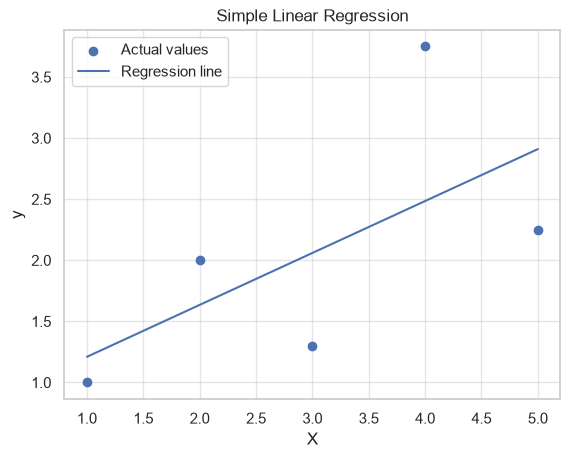

In [8]:
# TODO: Visualizing the results (scatter plot and regression line)

plt.scatter(X[:, 0], y, label="Actual values")
plt.plot(X[:, 0], y_pred, label="Regression line")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

### 1.2 Multiple Linear Regression

In [9]:
X = np.array(
    [
        [1,1,1],
        [1,1,2],
        [1,2,2],
        [1,0,1]
    ]
)

Y = np.array([
    3.25,
    6.5,
    3.5,
    5.0
])

In [10]:
class MultipleLinearRegression:
    def fit(self, X, y):
        self.coefficients = np.linalg.pinv(X) @ y

    def predict(self, X):
        return X @ self.coefficients


In [11]:
# TODO: Predicting using MultipleLinearRegression
multiple_model = MultipleLinearRegression()
multiple_model.fit(X, Y)
multiple_pred = multiple_model.predict(X)

print("Coefficients:", np.round(multiple_model.coefficients, 3))
print("Actual values:", Y)
print("Predictions:", np.round(multiple_pred, 3))

Coefficients: [ 2.062 -2.375  3.25 ]
Actual values: [3.25 6.5  3.5  5.  ]
Predictions: [2.937 6.188 3.812 5.312]


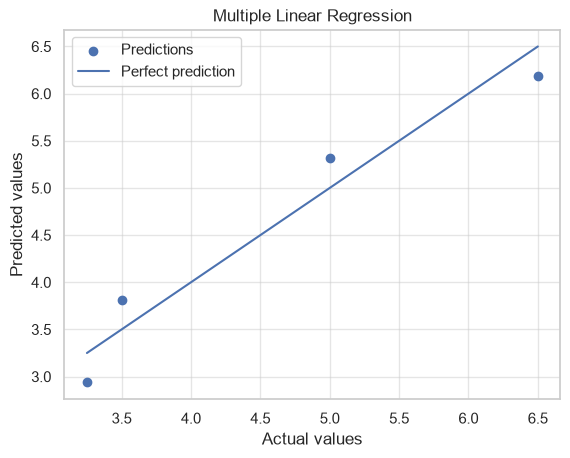

In [42]:
# TODO: VIsualizing the results (scatter plot and regression line)
plt.scatter(Y, multiple_pred, label="Predictions")

plt.plot(
    [Y.min(), Y.max()],
    [Y.min(), Y.max()],
    label="Perfect prediction"
)

plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Multiple Linear Regression")
plt.legend()
plt.show()

### 1.3 Gradient Descent

In [13]:
# TODO: Implement gradient descent algorithm
def gradient_descent(
    starting_point,
    gradient_func,
    learning_rate,
    max_iter,
    tolerance
):
    x = starting_point
    history = [x]

    for i in range(max_iter):
        new_x = x - learning_rate * gradient_func(x)
        history.append(new_x)

        if abs(new_x - x) < tolerance:
            x = new_x
            break

        x = new_x

    return history, x

In [14]:
def func(x):
    return x**2 - 4*x + 1

def grad_func(x):
    return 2*x - 4


Optimized result: 1.976941569907863


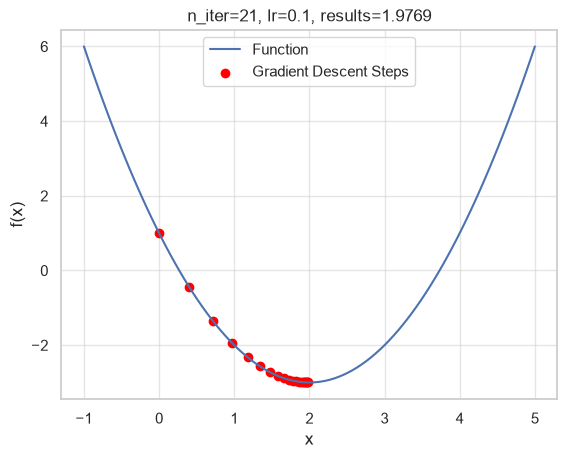

In [46]:
lr = 0.1

history, result = gradient_descent(
    starting_point=0.0,
    gradient_func=grad_func,
    learning_rate=lr,
    max_iter=20,
    tolerance=1e-6
)
print("Optimized result:", result)

history_array = np.array(history)
x_vals = np.linspace(-1, 5, 100)
y_vals = func(x_vals)

plt.plot(x_vals, y_vals, label='Function')
plt.scatter(history_array, func(history_array), color='red', label='Gradient Descent Steps')
plt.legend()
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title(f'n_iter={len(history)}, lr={lr}, results={result:.4f}')

plt.show()

## 2. Using scikit-learn

### 2.1. Load dataset

- In this lab, we use dataset [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) (id=9).
- We want to predict Miles Per Gallon (MPG) - a measure of a vehicle's fuel efficiency. It shows how many miles a car can travel on one gallon of fuel. A higher MPG means a car is more fuel-efficient, travels further on less fuel, and can result in lower running costs.

In [47]:
from ucimlrepo import fetch_ucirepo

auto_mpg = fetch_ucirepo(id=9)

X = auto_mpg.data.features
y = auto_mpg.data.targets

In [18]:
auto_mpg.metadata

{'uci_id': 9,
 'name': 'Auto MPG',
 'repository_url': 'https://archive.ics.uci.edu/dataset/9/auto+mpg',
 'data_url': 'https://archive.ics.uci.edu/static/public/9/data.csv',
 'abstract': 'Revised from CMU StatLib library, data concerns city-cycle fuel consumption',
 'area': 'Other',
 'tasks': ['Regression'],
 'characteristics': ['Multivariate'],
 'num_instances': 398,
 'num_features': 7,
 'feature_types': ['Real', 'Categorical', 'Integer'],
 'demographics': [],
 'target_col': ['mpg'],
 'index_col': ['car_name'],
 'has_missing_values': 'yes',
 'missing_values_symbol': 'NaN',
 'year_of_dataset_creation': 1993,
 'last_updated': 'Thu Aug 10 2023',
 'dataset_doi': '10.24432/C5859H',
 'creators': ['R. Quinlan'],
 'intro_paper': None,
 'additional_info': {'summary': 'This dataset is a slightly modified version of the dataset provided in the StatLib library.  In line with the use by Ross Quinlan (1993) in predicting the attribute "mpg", 8 of the original instances were removed because they had 

In [19]:
auto_mpg.variables

,name,role,type,demographic,description,units,missing_values
0,displacement,Feature,Continuous,None,None,None,no
1,mpg,Target,Continuous,None,None,None,no
2,cylinders,Feature,Integer,None,None,None,no
3,horsepower,Feature,Continuous,None,None,None,yes
4,weight,Feature,Continuous,None,None,None,no
5,acceleration,Feature,Continuous,None,None,None,no
6,model_year,Feature,Integer,None,None,None,no
7,origin,Feature,Integer,None,None,None,no
8,car_name,ID,Categorical,None,None,None,no


In [20]:
X.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin
0,307.0,8,130.0,3504,12.0,70,1
1,350.0,8,165.0,3693,11.5,70,1
2,318.0,8,150.0,3436,11.0,70,1
3,304.0,8,150.0,3433,12.0,70,1
4,302.0,8,140.0,3449,10.5,70,1


In [21]:
y.head()

,mpg
0,18.0
1,15.0
2,18.0
3,16.0
4,17.0


### 2.2. EDA

#### General sanity check

In [52]:
df = pd.concat([X, y], axis=1)

In [53]:
df.isna().sum()

displacement    0
cylinders       0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64

In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   displacement  398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   horsepower    392 non-null    float64
 3   weight        398 non-null    int64  
 4   acceleration  398 non-null    float64
 5   model_year    398 non-null    int64  
 6   origin        398 non-null    int64  
 7   mpg           398 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 25.0 KB


In [25]:
df.describe()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
count,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,193.425879,5.454774,104.469388,2970.424623,15.568090,76.010050,1.572864,23.514573
std,104.269838,1.701004,38.491160,846.841774,2.757689,3.697627,0.802055,7.815984
min,68.000000,3.000000,46.000000,1613.000000,8.000000,70.000000,1.000000,9.000000
25%,104.250000,4.000000,75.000000,2223.750000,13.825000,73.000000,1.000000,17.500000
50%,148.500000,4.000000,93.500000,2803.500000,15.500000,76.000000,1.000000,23.000000
75%,262.000000,8.000000,126.000000,3608.000000,17.175000,79.000000,2.000000,29.000000
max,455.000000,8.000000,230.000000,5140.000000,24.800000,82.000000,3.000000,46.600000


In [26]:
df.sample(5)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
60,140.0,4,90.0,2408,19.5,72,1,20.0
197,90.0,4,70.0,1937,14.2,76,2,29.0
205,97.0,4,75.0,2155,16.4,76,3,28.0
397,119.0,4,82.0,2720,19.4,82,1,31.0
382,108.0,4,70.0,2245,16.9,82,3,34.0


In [27]:
df['origin'].unique()

array([1, 3, 2])

In [28]:
# Check cases where 'horsepower' is missing
df[df['horsepower'].isna()]

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
32,98.0,4,NaN,2046,19.0,71,1,25.0
126,200.0,6,NaN,2875,17.0,74,1,21.0
330,85.0,4,NaN,1835,17.3,80,2,40.9
336,140.0,4,NaN,2905,14.3,80,1,23.6
354,100.0,4,NaN,2320,15.8,81,2,34.5
374,151.0,4,NaN,3035,20.5,82,1,23.0


In [56]:
# Fill missing 'horsepower' values with the median
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())
df.isna().sum()

displacement    0
cylinders       0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64

In [57]:
df.iloc[32,:]

displacement      98.0
cylinders          4.0
horsepower        93.5
weight          2046.0
acceleration      19.0
model_year        71.0
origin             1.0
mpg               25.0
Name: 32, dtype: float64

#### Univariate analysis

Study the distribution of each variable individually

array([[<Axes: title={'center': 'displacement'}>,
        <Axes: title={'center': 'horsepower'}>],
       [<Axes: title={'center': 'weight'}>,
        <Axes: title={'center': 'acceleration'}>],
       [<Axes: title={'center': 'mpg'}>, <Axes: >]], dtype=object)

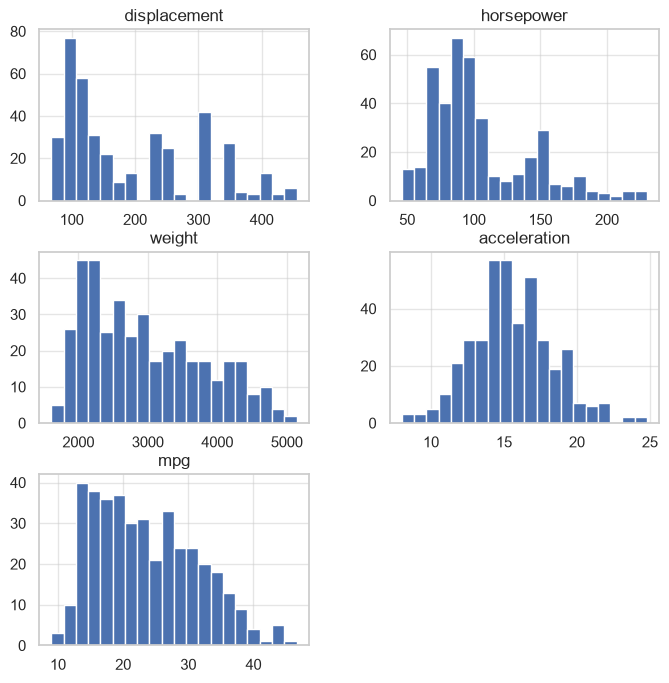

In [31]:
# Check distribution of numerical columns
cat_cols = ['cylinders', 'model_year', 'origin']
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
num_cols = [col for col in num_cols if col not in cat_cols]

df[num_cols].hist(bins=20, figsize=(8,8))

Unique values in cylinders: [8 4 6 3 5]
Unique values in model_year: [70 71 72 73 74 75 76 77 78 79 80 81 82]
Unique values in origin: [1 3 2]


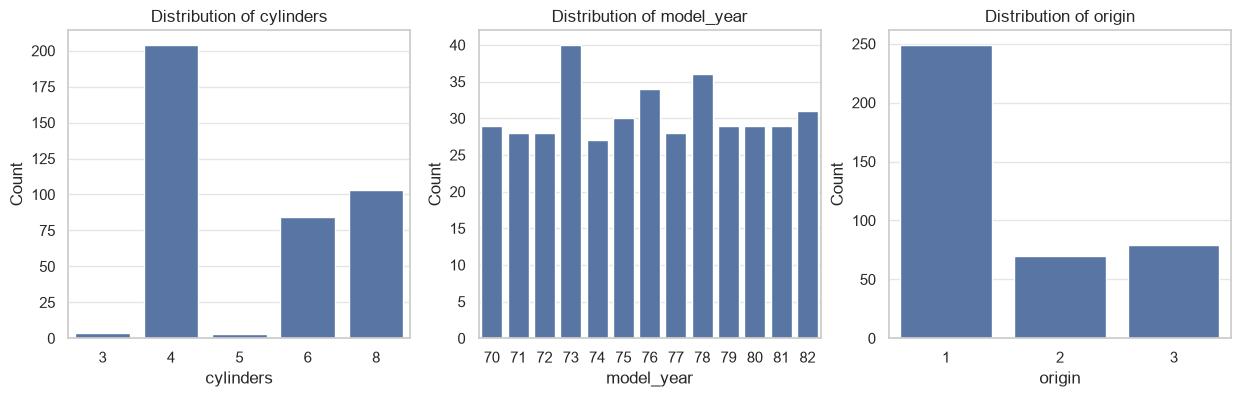

In [32]:
# Check unique values in categorical columns
for col in cat_cols:
    print(f"Unique values in {col}: {df[col].unique()}")

# Check distributin of unque values in categorical columns
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(cat_cols):
    sns.countplot(x=col, data=df, ax=axs[i])
    axs[i].set_title(f'Distribution of {col}')
    axs[i].set_xlabel(col)
    axs[i].set_ylabel('Count')

### 2.4. Multivariate analysis

Explore interactions among multiple features

<Axes: >

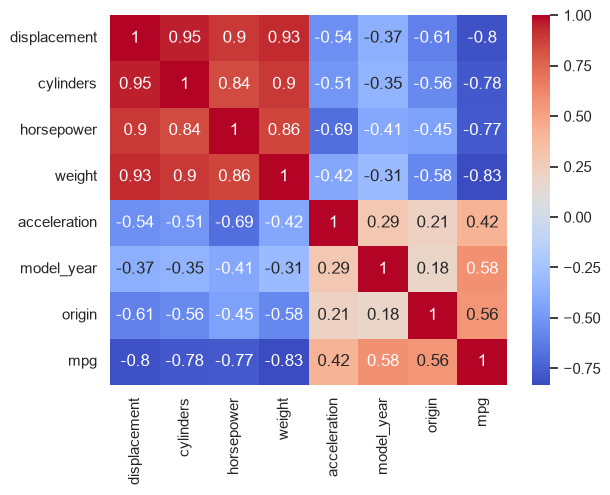

In [33]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

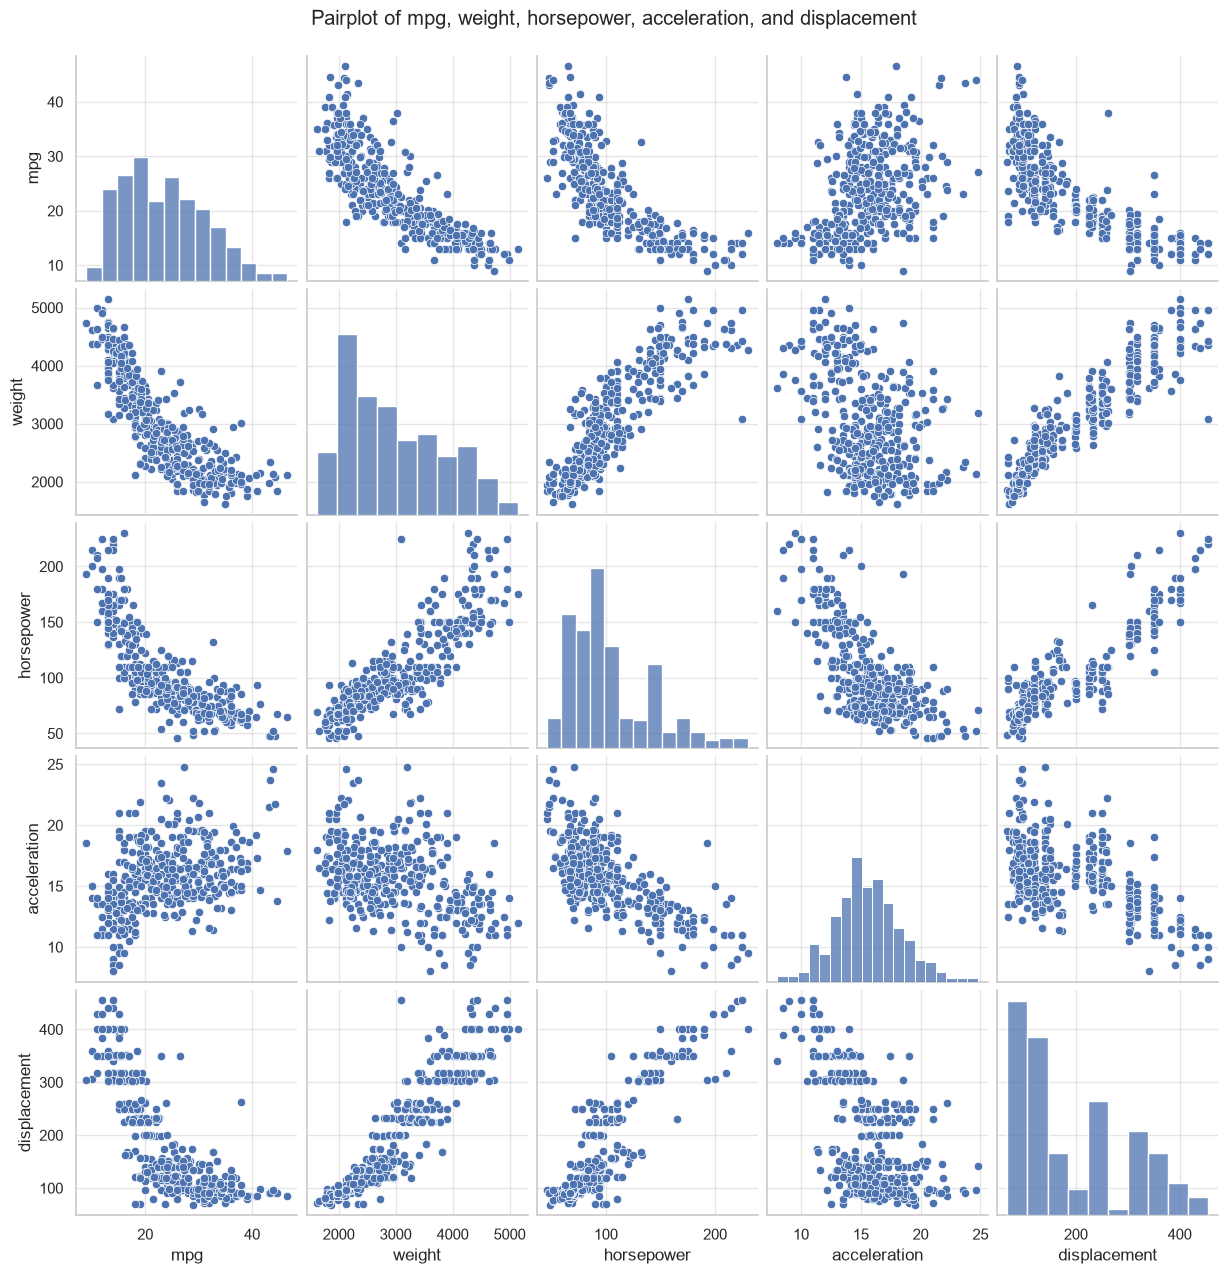

In [34]:
# (a) Pairplot of selected features
cols_pair = ['mpg', 'weight', 'horsepower', 'acceleration', 'displacement']
sns.pairplot(df[cols_pair].dropna(), diag_kind='hist')
plt.suptitle("Pairplot of mpg, weight, horsepower, acceleration, and displacement", y=1.02)
plt.show()

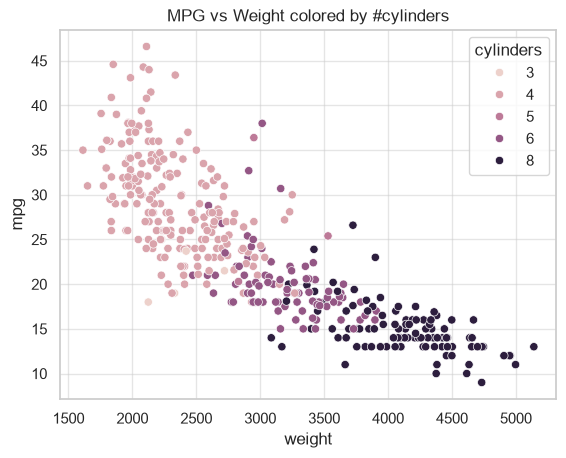

In [35]:
# (b) Scatter: mpg vs weight, colored by cylinders
sns.scatterplot(
    data=df,
    x='weight',
    y='mpg',
    hue='cylinders',
)
plt.title("MPG vs Weight colored by #cylinders")
plt.show()

## 3. Feature engineering

In [36]:
# TODO: Select features, make all features numeric and normalize values to the same range if necessary
X = df.drop(columns="mpg")
y = df["mpg"]

X = pd.get_dummies(X, columns=["origin"], dtype=int)

print("Features used for training:")
print(X.head())
print("Target values:")
print(y.head())


Features used for training:
   displacement  cylinders  horsepower  weight  acceleration  model_year  \
0         307.0          8       130.0    3504          12.0          70   
1         350.0          8       165.0    3693          11.5          70   
2         318.0          8       150.0    3436          11.0          70   
3         304.0          8       150.0    3433          12.0          70   
4         302.0          8       140.0    3449          10.5          70   

   origin_1  origin_2  origin_3  
0         1         0         0  
1         1         0         0  
2         1         0         0  
3         1         0         0  
4         1         0         0  
Target values:
0    18.0
1    15.0
2    18.0
3    16.0
4    17.0
Name: mpg, dtype: float64


## 4. Model training

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 318
Testing samples: 80


In [58]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[ 7.65,-0.83,-2.61,...,-1.87, 1.07, 0.8 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,27.19
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](9,)","[12.86, 7.81, 6.5 ,..., 0.97, 0.87, 0. ]"


## 5. Evaluatation

   Actual MPG  Predicted MPG
0        33.0          32.49
1        28.0          29.20
2        19.0          21.25
3        13.0          16.83
4        14.0          12.34
5        27.0          26.58
6        24.0          27.56
7        13.0          10.06
8        17.0          16.64
9        21.0          21.76


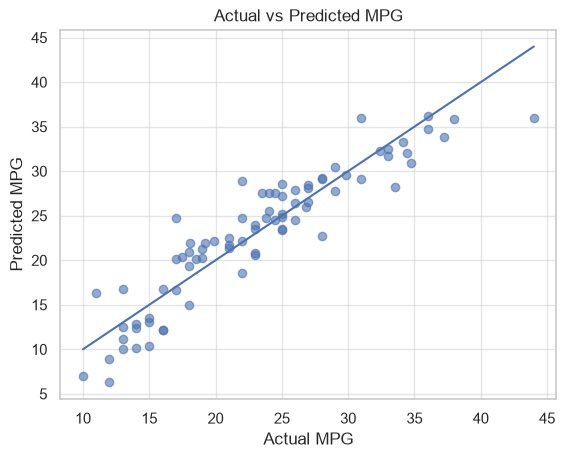

In [39]:
#TODO: Predicting on the test set using the fitted model
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual MPG": y_test.to_numpy(),
    "Predicted MPG": y_pred
})
print(comparison.head(10).round(2))

plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()])
plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted MPG")
plt.show()

In [59]:
# TODO: Calculate evaluation metrics (MAE, MSE, RMSE, R2)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2: {r2:.3f}")

MAE: 2.29
MSE: 8.34
RMSE: 2.89
R2: 0.845
